In [ ]:
import math
import torch
import torch.nn as nn
import tiktoken

# ---------- Config (must match training) ----------
GPT_CONFIG_163M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

# ---------- Model ----------
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, _ = x.shape
        keys = self.W_key(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        queries = self.W_query(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        values = self.W_value(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        context_vec = torch.nn.functional.scaled_dot_product_attention(
            queries, keys, values,
            dropout_p=self.dropout.p if self.training else 0.0,
            is_causal=True,
        ).transpose(1, 2)
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        return self.out_proj(context_vec)


class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        return torch.nn.functional.layer_norm(
            x, self.scale.shape, self.scale, self.shift, self.eps
        )


class GELU(nn.Module):
    def forward(self, x):
        return torch.nn.functional.gelu(x, approximate="tanh")


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"], d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"],
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.drop_shortcut(self.att(self.norm1(x))) + shortcut
        shortcut = x
        x = self.drop_shortcut(self.ff(self.norm2(x))) + shortcut
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        _, seq_len = in_idx.shape
        x = self.tok_emb(in_idx) + self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        return self.out_head(x)


# ---------- Tokenizer helpers ----------
tokenizer = tiktoken.get_encoding("gpt2")

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    return torch.tensor(encoded).unsqueeze(0)

def format_input(entry):
    instruction_text = (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )
    input_text = f"\n\n### Input:\n{entry['input']}" if entry.get("input") else ""
    return instruction_text + input_text

# ---------- Load fine-tuned weights ----------
CKPT = "my-finetuned-gpt.pth"
chat_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load(CKPT, map_location=chat_device, weights_only=True))
chat_model.to(chat_device).eval()
print("Loaded:", CKPT, "on", chat_device)

model = chat_model   # the patching cells below use this name


In [8]:
import torch, tiktoken
import matplotlib.pyplot as plt

tok = tiktoken.get_encoding("gpt2")
device = next(model.parameters()).device
model.eval()

def build(country):
    return (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\ncapital of {country.lower()}"
        "\n\n### Response:\n"
        f"The capital of {country} is"
    )

In [9]:
def top_k(prompt, k=10):
    ids = torch.tensor([tok.encode(prompt)], device=device)
    with torch.no_grad():
        logits = model(ids)[0, -1]
    top = logits.softmax(-1).topk(k)
    print(repr(prompt[-40:]))
    for prob, i in zip(top.values, top.indices):
        print(f"   {tok.decode([i.item()])!r:14} {prob.item():.3f}")
    return logits

answers = {"France": " Paris", "Italy": " Rome", "India": " Delhi",
           "Germany": " Berlin", "Japan": " Tokyo"}
for c in answers.values():
    assert len(tok.encode(c)) == 1, f"{c!r} is multi-token"

paris = tok.encode(" Paris")[0]
for country, city in answers.items():
    logits = top_k(build(country))
    cid = tok.encode(city)[0]
    print(f"   >>> logit({city.strip()}) - logit(Paris) = {(logits[cid] - logits[paris]).item():.2f}\n")

'\n\n### Response:\nThe capital of France is'
   ' Paris'       0.823
   ' France'      0.024
   ' the'         0.018
   ' "'           0.007
   " '"           0.004
   ' E'           0.004
   ' Lou'         0.002
   ' a'           0.002
   ' ['           0.002
   ' French'      0.002
   >>> logit(Paris) - logit(Paris) = 0.00

'y\n\n### Response:\nThe capital of Italy is'
   ' Paris'       0.539
   ' Rome'        0.049
   ' the'         0.029
   ' Italy'       0.025
   ' Florence'    0.018
   ' "'           0.017
   " '"           0.010
   ' P'           0.008
   ' France'      0.008
   ' ['           0.005
   >>> logit(Rome) - logit(Paris) = -2.39

'a\n\n### Response:\nThe capital of India is'
   ' Paris'       0.330
   ' the'         0.052
   ' "'           0.032
   ' India'       0.027
   " '"           0.016
   ' a'           0.012
   ' New'         0.011
   ' ['           0.008
   ' May'         0.006
   ' China'       0.005
   >>> logit(Delhi) - logit(Paris) = -9.92

'\n### Respo

metric on source (Italy): -2.39
metric on base   (France): -6.48


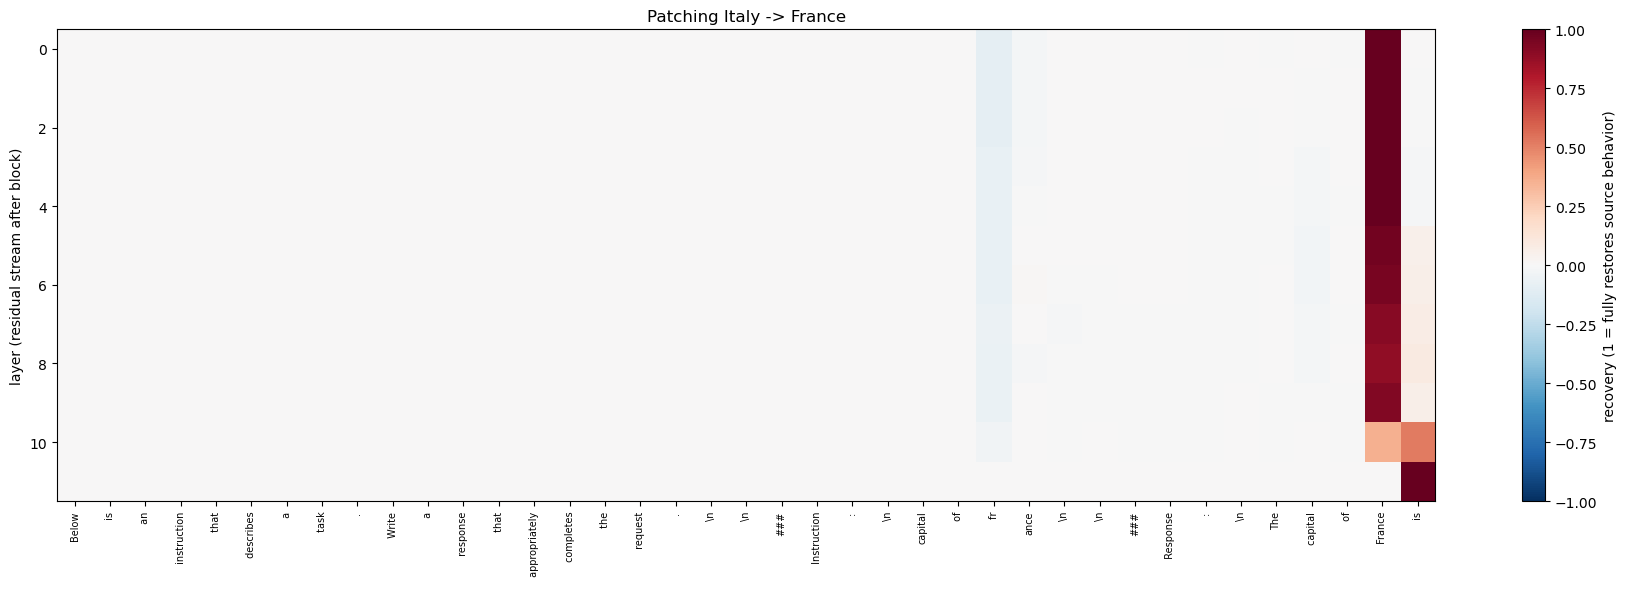

In [ ]:
SRC, BASE = "Italy", "France"           
SRC_ANS, BASE_ANS = " Rome", " Paris"

def ids(c):
    return torch.tensor([tok.encode(build(c))], device=device)

src_ids, base_ids = ids(SRC), ids(BASE)
assert src_ids.shape == base_ids.shape, "prompts must tokenize to the same length"
T = src_ids.shape[1]
for a in (SRC_ANS, BASE_ANS):
    assert len(tok.encode(a)) == 1, f"{a!r} is multi-token"
src_t, base_t = tok.encode(SRC_ANS)[0], tok.encode(BASE_ANS)[0]

def metric(logits):                      
    return (logits[0, -1, src_t] - logits[0, -1, base_t]).item()

blocks = model.trf_blocks                
L = len(blocks)

# cache residual stream after every block on the SOURCE prompt
cache, hooks = {}, []
for l, b in enumerate(blocks):
    hooks.append(b.register_forward_hook(
        lambda m, i, o, l=l: cache.__setitem__(l, o.detach().clone())))
with torch.no_grad():
    m_src = metric(model(src_ids))
for h in hooks: h.remove()

with torch.no_grad():
    m_base = metric(model(base_ids))

print(f"metric on source ({SRC}): {m_src:.2f}")
print(f"metric on base   ({BASE}): {m_base:.2f}")
assert abs(m_src - m_base) > 0.5, "no gap between prompts -> nothing to patch"

# patch one (layer, position) at a time into the BASE run
def patched_metric(l, pos):
    def hook(m, i, o):
        o = o.clone()
        o[:, pos] = cache[l][:, pos]
        return o                         # returning is what makes the patch take effect
    h = blocks[l].register_forward_hook(hook)
    with torch.no_grad():
        val = metric(model(base_ids))
    h.remove()
    return val

grid = torch.zeros(L, T)
for l in range(L):
    for p in range(T):
        grid[l, p] = (patched_metric(l, p) - m_base) / (m_src - m_base)

# heatmap
labels = [tok.decode([t]).replace("\n", "\\n") for t in base_ids[0].tolist()]
plt.figure(figsize=(18, 6))
plt.imshow(grid.numpy(), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="recovery (1 = fully restores source behavior)")
plt.xticks(range(T), labels, rotation=90, fontsize=7)
plt.ylabel("layer (residual stream after block)")
plt.title(f"Patching {SRC} -> {BASE}")
plt.tight_layout(); plt.savefig("patching_heatmap.png", dpi=150); plt.show()

In [11]:
diff = (src_ids[0] != base_ids[0]).nonzero().flatten().tolist()
print("differing positions:", diff, [tok.decode([base_ids[0, p].item()]) for p in diff])
instr_pos = diff[:-1]      # country tokens in the instruction
resp_pos  = diff[-1]       # country token in the response prefix

def patch_many(l, positions):
    def hook(m, i, o):
        o = o.clone()
        for p in positions:
            o[:, p] = cache[l][:, p]
        return o
    h = blocks[l].register_forward_hook(hook)
    with torch.no_grad():
        val = metric(model(base_ids))
    h.remove()
    return (val - m_base) / (m_src - m_base)

print("layer | instruction (all tokens) | response country | both")
for l in range(L):
    print(f"{l:5d} | {patch_many(l, instr_pos):24.2f} | {patch_many(l, [resp_pos]):16.2f} | {patch_many(l, instr_pos + [resp_pos]):.2f}")

differing positions: [26, 27, 37] [' fr', 'ance', ' France']
layer | instruction (all tokens) | response country | both
    0 |                    -0.10 |             1.05 | 1.00
    1 |                    -0.09 |             1.05 | 1.00
    2 |                    -0.09 |             1.05 | 1.01
    3 |                    -0.07 |             1.04 | 1.02
    4 |                    -0.06 |             1.04 | 1.03
    5 |                    -0.07 |             0.96 | 0.96
    6 |                    -0.06 |             0.95 | 0.96
    7 |                    -0.06 |             0.91 | 0.92
    8 |                    -0.07 |             0.89 | 0.88
    9 |                    -0.07 |             0.93 | 0.92
   10 |                    -0.04 |             0.36 | 0.34
   11 |                     0.00 |             0.00 | 0.00


In [12]:
pairs = {"Italy": " Rome", "Germany": " Berlin", "Japan": " Tokyo", "India": " Delhi"}
BASE, BASE_ANS = "France", " Paris"
base_ids = ids(BASE)
base_t = tok.encode(BASE_ANS)[0]

def run_pair(SRC, ANS):
    s_ids = ids(SRC)
    if s_ids.shape != base_ids.shape or len(tok.encode(ANS)) != 1:
        print(f"\nskip {SRC} (token length mismatch)"); return
    s_t = tok.encode(ANS)[0]
    m = lambda lg: (lg[0, -1, s_t] - lg[0, -1, base_t]).item()

    cache, hooks = {}, []
    for l, b in enumerate(blocks):
        hooks.append(b.register_forward_hook(
            lambda mod, i, o, l=l: cache.__setitem__(l, o.detach().clone())))
    with torch.no_grad(): m_s = m(model(s_ids))
    for h in hooks: h.remove()
    with torch.no_grad(): m_b = m(model(base_ids))

    gap = m_s - m_b
    if abs(gap) < 0.5:
        print(f"\nskip {SRC}: gap {gap:.2f} too small to patch"); return

    diff = (s_ids[0] != base_ids[0]).nonzero().flatten().tolist()
    instr, resp = diff[:-1], [diff[-1]]

    def rec(l, pos):
        def hook(mod, i, o):
            o = o.clone()
            for p in pos: o[:, p] = cache[l][:, p]
            return o
        h = blocks[l].register_forward_hook(hook)
        with torch.no_grad(): v = m(model(base_ids))
        h.remove()
        return (v - m_b) / gap

    print(f"\n{SRC}: gap = {gap:.2f}")
    print("layer | instruction | response country")
    for l in [0, 4, 8, 9, 10, 11]:
        print(f"{l:5d} | {rec(l, instr):11.2f} | {rec(l, resp):.2f}")

for s, a in pairs.items():
    run_pair(s, a)


Italy: gap = 4.09
layer | instruction | response country
    0 |       -0.10 | 1.05
    4 |       -0.06 | 1.04
    8 |       -0.07 | 0.89
    9 |       -0.07 | 0.93
   10 |       -0.04 | 0.36
   11 |        0.00 | 0.00

skip Germany (token length mismatch)

Japan: gap = 7.23
layer | instruction | response country
    0 |        0.30 | 0.87
    4 |        0.29 | 0.85
    8 |        0.25 | 0.69
    9 |        0.25 | 0.70
   10 |        0.07 | 0.19
   11 |        0.00 | 0.00

India: gap = 3.85
layer | instruction | response country
    0 |        0.01 | 0.99
    4 |        0.02 | 0.99
    8 |       -0.01 | 0.85
    9 |       -0.04 | 0.80
   10 |       -0.02 | 0.23
   11 |        0.00 | 0.00
